Dataset Shape: (144, 2)

--- First 3 Entries ---
     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132

--- Random Sampling of 5 Rows ---
            Passengers
Month                 
1958-10-01         359
1950-08-01         170
1955-11-01         237
1957-02-01         301
1953-09-01         237

--- Time-based Indexing (First 3 entries of 1955) ---
            Passengers
Month                 
1955-01-01         242
1955-02-01         233
1955-03-01         267


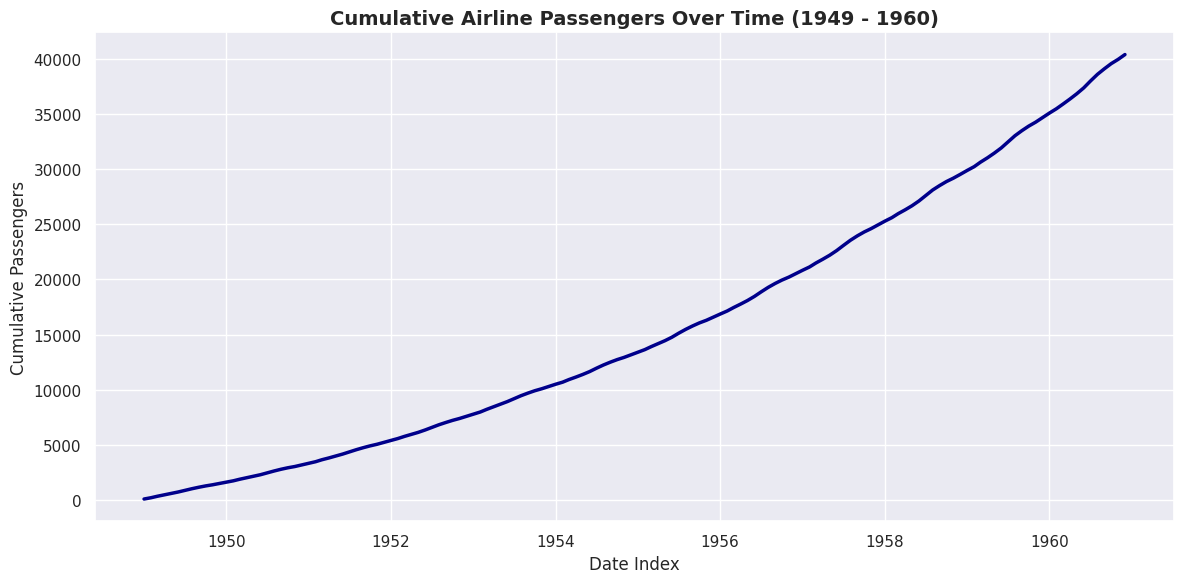

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the provided dataset
df = pd.read_csv('airline_passengers.csv')

# 2. Check the shape of the dataset
print(f"Dataset Shape: {df.shape}")

# 3. Check a few entries inside the dataframe
print("\n--- First 3 Entries ---")
print(df.head(3))

# 4. Change the index of our dataframe to the 'month' column
# Also, converting it to datetime type ensures robust time-based indexing operations
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)

# 5. Display a random sampling of 5 rows
print("\n--- Random Sampling of 5 Rows ---")
print(df.sample(5, random_state=42))

# 6. Do Time-based indexing (Example: Slicing the data for the entire year of 1955)
print("\n--- Time-based Indexing (First 3 entries of 1955) ---")
print(df.loc['1955'].head(3))

# 7. Perform a cumulative sum over the passenger list
df['cumulative_passengers'] = df['Passengers'].cumsum()

# 8. Use the Seaborn library to plot the time series data
sns.set_theme(style="darkgrid")
plt.figure(figsize=(12, 6))

# Plotting the cumulative sum over time
sns.lineplot(data=df, x=df.index, y='cumulative_passengers', color='darkblue', linewidth=2.5)

plt.title('Cumulative Airline Passengers Over Time (1949 - 1960)', fontsize=14, fontweight='bold')
plt.xlabel('Date Index', fontsize=12)
plt.ylabel('Cumulative Passengers', fontsize=12)
plt.tight_layout()
plt.show()

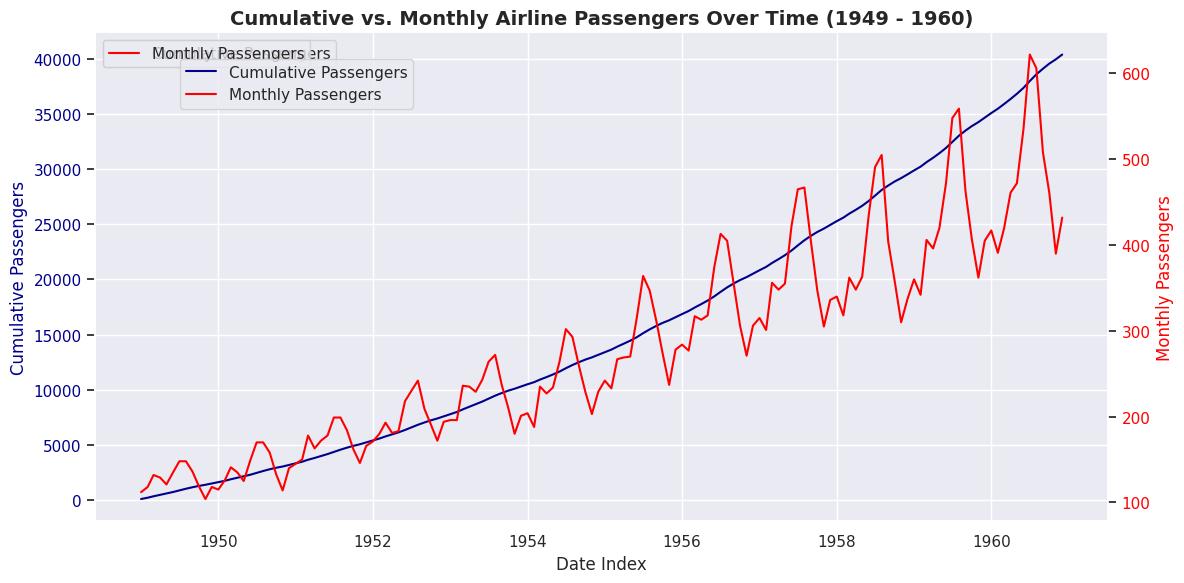

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

sns.lineplot(data=df, x=df.index, y='cumulative_passengers', ax=ax1, color='darkblue', label='Cumulative Passengers')
ax1.set_xlabel('Date Index', fontsize=12)
ax1.set_ylabel('Cumulative Passengers', color='darkblue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='darkblue')

# Create a second y-axis
ax2 = ax1.twinx()
sns.lineplot(data=df, x=df.index, y='Passengers', ax=ax2, color='red', label='Monthly Passengers')
ax2.set_ylabel('Monthly Passengers', color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

# Add titles and legend
plt.title('Cumulative vs. Monthly Airline Passengers Over Time (1949 - 1960)', fontsize=14, fontweight='bold')
fig.legend(loc='upper left', bbox_to_anchor=(0.15, 0.9))

plt.grid(True, linestyle='--', alpha=0.0)
plt.tight_layout()
plt.show()

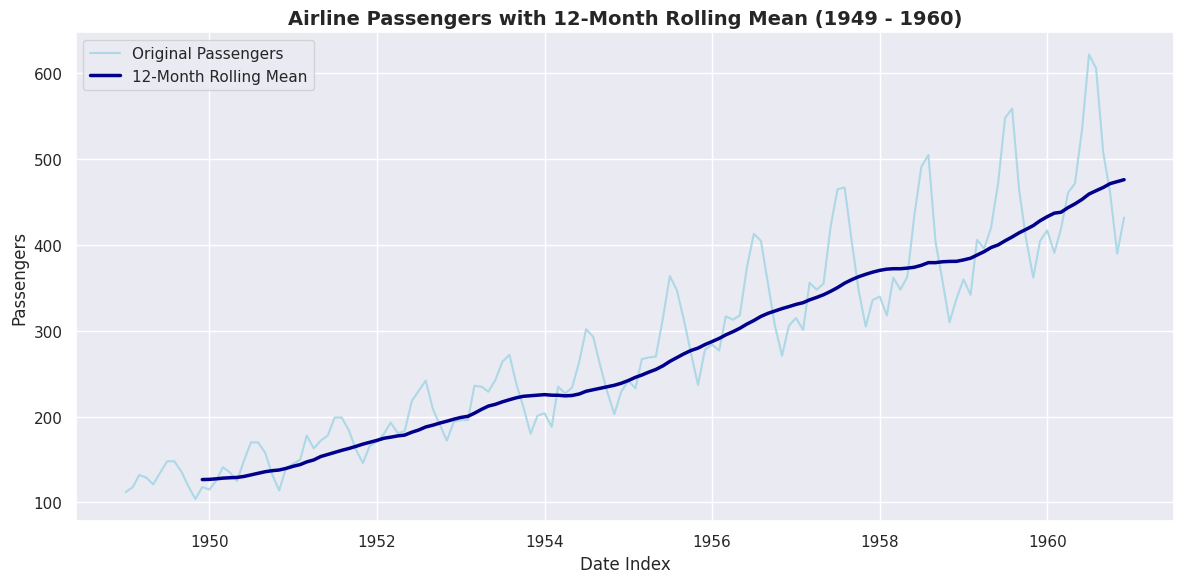

In [ ]:
# Calculate the 12-month rolling mean of 'Passengers'
df['Passengers_rolling_mean'] = df['Passengers'].rolling(window=12).mean()

# Plot the original 'Passengers' and the rolling mean
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x=df.index, y='Passengers', label='Original Passengers', color='lightblue')
sns.lineplot(data=df, x=df.index, y='Passengers_rolling_mean', label='12-Month Rolling Mean', color='darkblue', linewidth=2.5)

plt.title('Airline Passengers with 12-Month Rolling Mean (1949 - 1960)', fontsize=14, fontweight='bold')
plt.xlabel('Date Index', fontsize=12)
plt.ylabel('Passengers', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

### Check for missing values in 'Passengers' column

In [ ]:
missing_values = df['Passengers'].isnull().sum()
print(f"Number of missing values in 'Passengers' column: {missing_values}")

### Visualize outliers in 'Passengers' column using a box plot

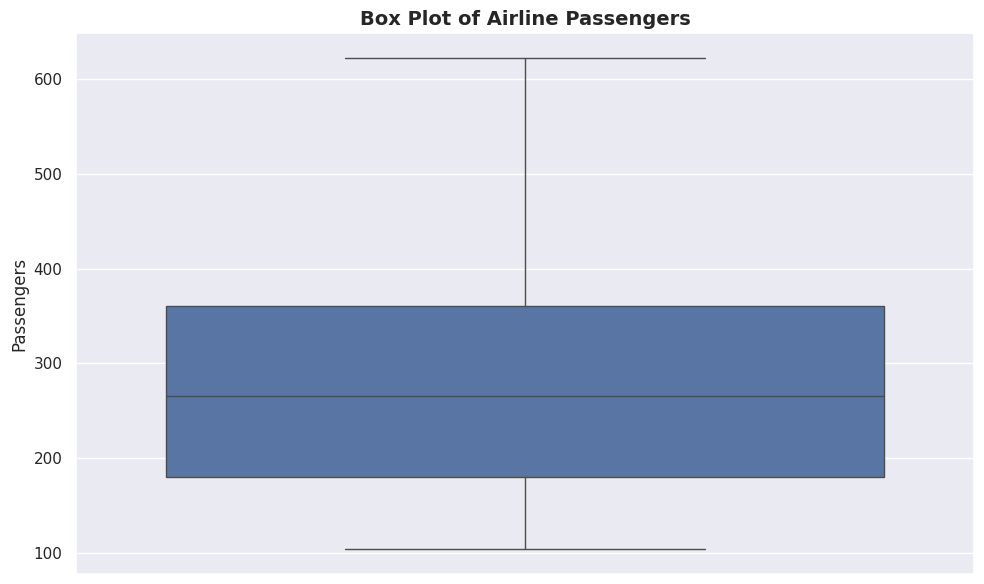

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Passengers'])
plt.title('Box Plot of Airline Passengers', fontsize=14, fontweight='bold')
plt.ylabel('Passengers', fontsize=12)
plt.tight_layout()
plt.show()

### Identify outliers using Z-scores

In [ ]:
from scipy.stats import zscore

# Calculate Z-scores for the 'Passengers' column
df['Passengers_zscore'] = zscore(df['Passengers'])

# Define a threshold for outliers (e.g., Z-score > 3 or < -3)
outlier_threshold = 3

# Identify outlier rows
outliers = df[(df['Passengers_zscore'] > outlier_threshold) | (df['Passengers_zscore'] < -outlier_threshold)]

print(f"Outlier rows based on a Z-score threshold of {outlier_threshold}:")
if not outliers.empty:
    display(outliers[['Passengers', 'Passengers_zscore']])
else:
    print("No outliers found based on the specified Z-score threshold.")

Outlier rows based on a Z-score threshold of 3:
No outliers found based on the specified Z-score threshold.


### Plotting the distribution of 'Passengers' using a histogram

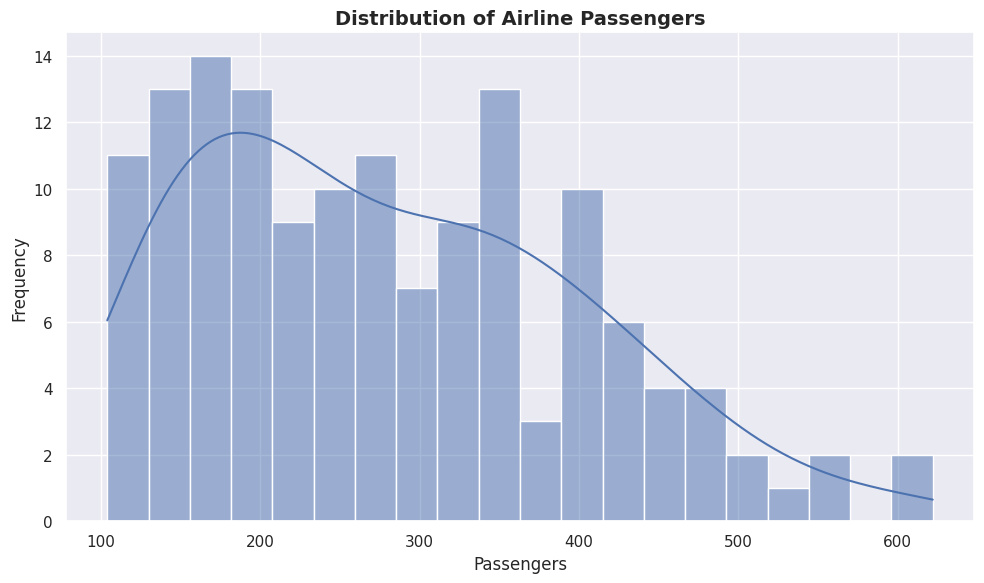

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Passengers'], kde=True, bins=20)
plt.title('Distribution of Airline Passengers', fontsize=14, fontweight='bold')
plt.xlabel('Passengers', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()
plt.show()

### Perform Seasonal Decomposition on 'Passengers' data

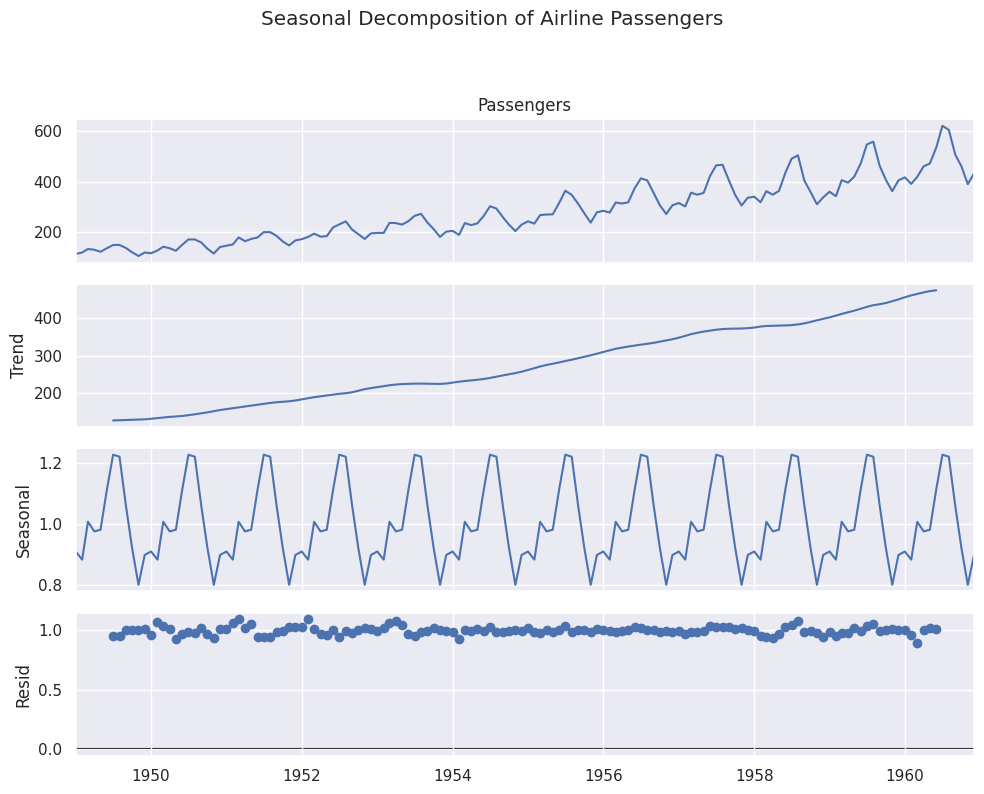

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform seasonal decomposition. The 'model' parameter can be 'additive' or 'multiplicative'.
# For data with increasing variance over time (like this dataset), 'multiplicative' is often more appropriate.
decomposition = seasonal_decompose(df['Passengers'], model='multiplicative', period=12)

# Plot the decomposed components
fig = decomposition.plot()
fig.set_size_inches(10, 8)
fig.suptitle('Seasonal Decomposition of Airline Passengers', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent title overlap
plt.show()

### Visualize Anomalies using Residuals from Seasonal Decomposition

After decomposing the time series into trend, seasonal, and residual components, anomalies can often be identified by examining the residuals. Points that fall significantly outside the typical range of residuals can be considered anomalies.

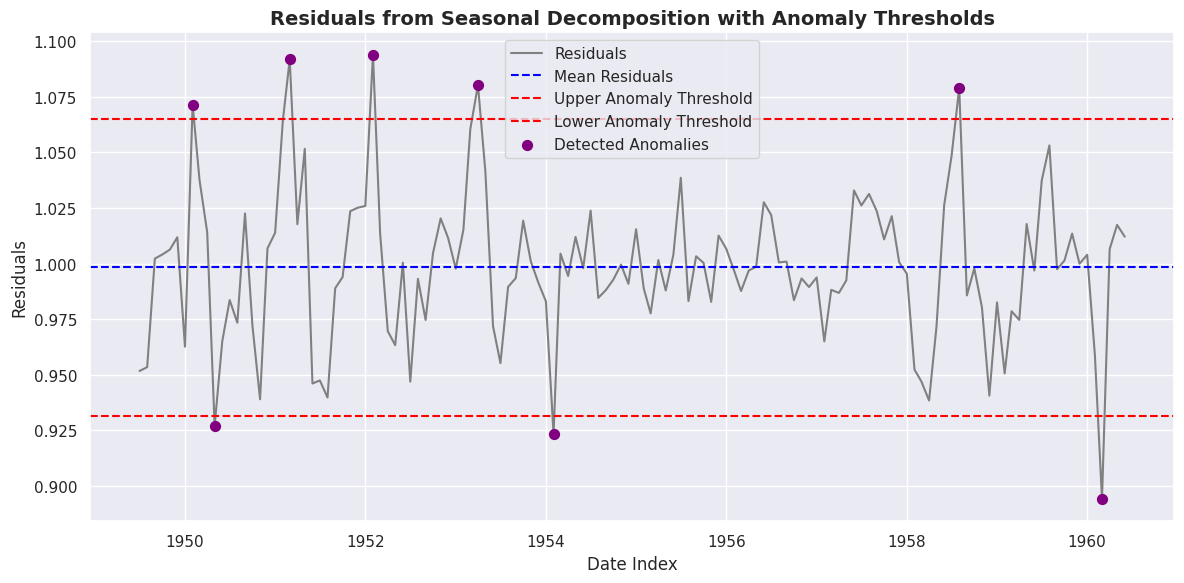

In [ ]:
residuals = decomposition.resid

# Calculate mean and standard deviation of residuals
mean_residuals = residuals.mean()
std_residuals = residuals.std()

# Define anomaly threshold (e.g., 2 standard deviations from the mean)
anomaly_threshold = 2 * std_residuals

# Identify anomalies in residuals
anomalies_in_residuals = residuals[(residuals > mean_residuals + anomaly_threshold) | (residuals < mean_residuals - anomaly_threshold)]

plt.figure(figsize=(12, 6))
plt.plot(residuals.index, residuals, label='Residuals', color='gray')
plt.axhline(y=mean_residuals, color='blue', linestyle='--', label='Mean Residuals')
plt.axhline(y=mean_residuals + anomaly_threshold, color='red', linestyle='--', label='Upper Anomaly Threshold')
plt.axhline(y=mean_residuals - anomaly_threshold, color='red', linestyle='--', label='Lower Anomaly Threshold')

# Plot identified anomalies
plt.scatter(anomalies_in_residuals.index, anomalies_in_residuals, color='purple', s=50, zorder=5, label='Detected Anomalies')

plt.title('Residuals from Seasonal Decomposition with Anomaly Thresholds', fontsize=14, fontweight='bold')
plt.xlabel('Date Index', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Display the identified anomaly points, if any
print("\n--- Detected Anomalies in Residuals ---")
if not anomalies_in_residuals.empty:
    display(anomalies_in_residuals)
else:
    print("No anomalies detected based on the 2-sigma threshold.")


--- Detected Anomalies in Residuals ---


,resid
Month,
1950-02-01,1.071467
1950-05-01,0.926903
1951-03-01,1.091854
1952-02-01,1.093970
1953-04-01,1.080233
1954-02-01,0.923203
1958-08-01,1.078970
1960-03-01,0.894086


### Visualize the Distribution of Residuals

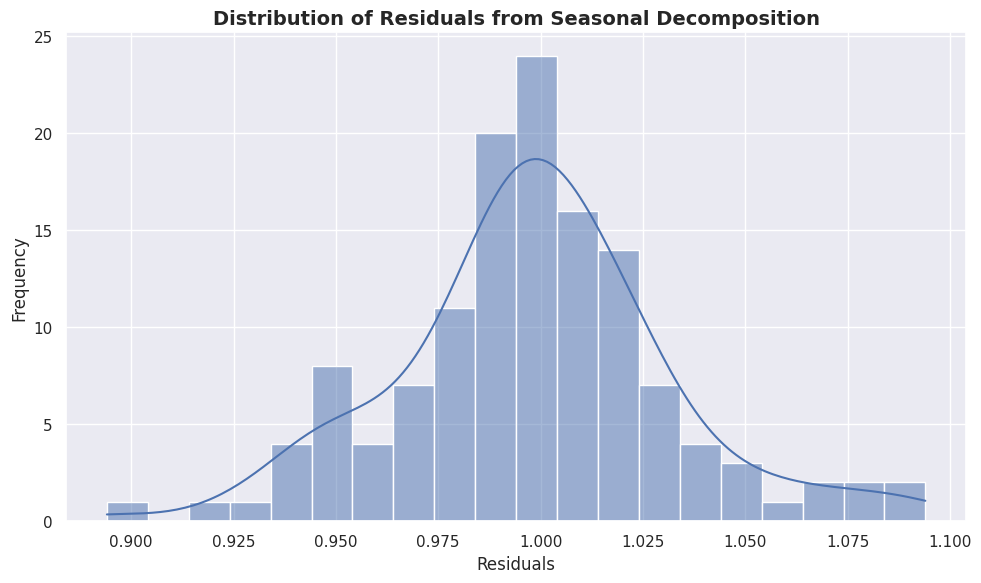

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(residuals.dropna(), kde=True, bins=20)
plt.title('Distribution of Residuals from Seasonal Decomposition', fontsize=14, fontweight='bold')
plt.xlabel('Residuals', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()
plt.show()

### Plotting ACF and PACF of Residuals

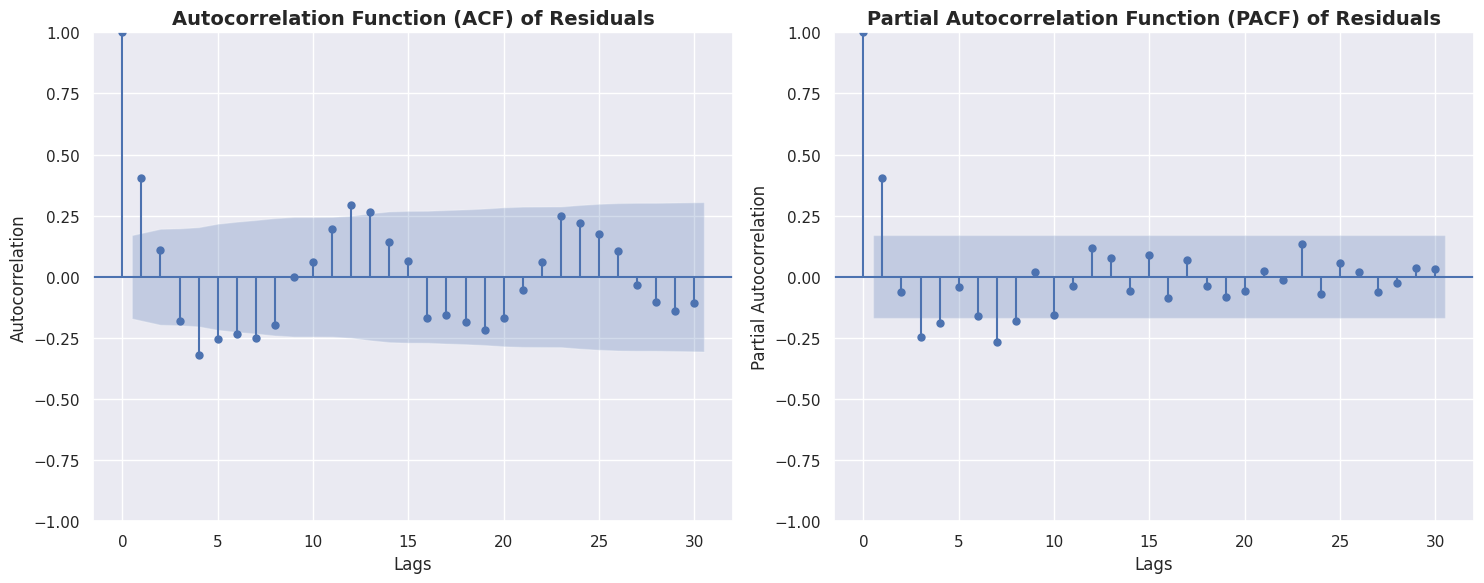

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot ACF
plot_acf(residuals.dropna(), lags=30, ax=axes[0])
axes[0].set_title('Autocorrelation Function (ACF) of Residuals', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Lags', fontsize=12)
axes[0].set_ylabel('Autocorrelation', fontsize=12)

# Plot PACF
plot_pacf(residuals.dropna(), lags=30, ax=axes[1])
axes[1].set_title('Partial Autocorrelation Function (PACF) of Residuals', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Lags', fontsize=12)
axes[1].set_ylabel('Partial Autocorrelation', fontsize=12)

plt.tight_layout()
plt.show()

### Forecast Future Values using SARIMAX Model

The Seasonal Autoregressive Integrated Moving Average with eXogenous regressors (SARIMAX) model is a popular time series forecasting model that extends the ARIMA model by incorporating seasonal components. For this dataset, a seasonal period of 12 (for months) is appropriate.

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Define the SARIMAX model parameters
# (p,d,q) are the non-seasonal orders
# (P,D,Q,S) are the seasonal orders, where S is the seasonal period (12 for monthly data)
order = (1, 1, 1)        # Example: (AR order, Differencing order, MA order)
seasonal_order = (1, 1, 1, 12) # Example: (Seasonal AR order, Seasonal Differencing order, Seasonal MA order, Seasonal period)

# Initialize and fit the SARIMAX model
# The 'enforce_stationarity=False' and 'enforce_invertibility=False' are often used
# to help the model converge, especially with initial parameter guesses.
model = SARIMAX(df['Passengers'], order=order, seasonal_order=seasonal_order,
                enforce_stationarity=False, enforce_invertibility=False)
model_fit = model.fit(disp=False) # disp=False suppresses convergence messages

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  144
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -456.103
Date:                            Tue, 22 Sep 2026   AIC                            922.205
Time:                                    07:26:46   BIC                            936.016
Sample:                                01-01-1949   HQIC                           927.812
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2298      0.401     -0.573      0.567      -1.016       0.557
ma.L1         -0.0987      0.374   

### Generate Predictions and Visualize Forecast

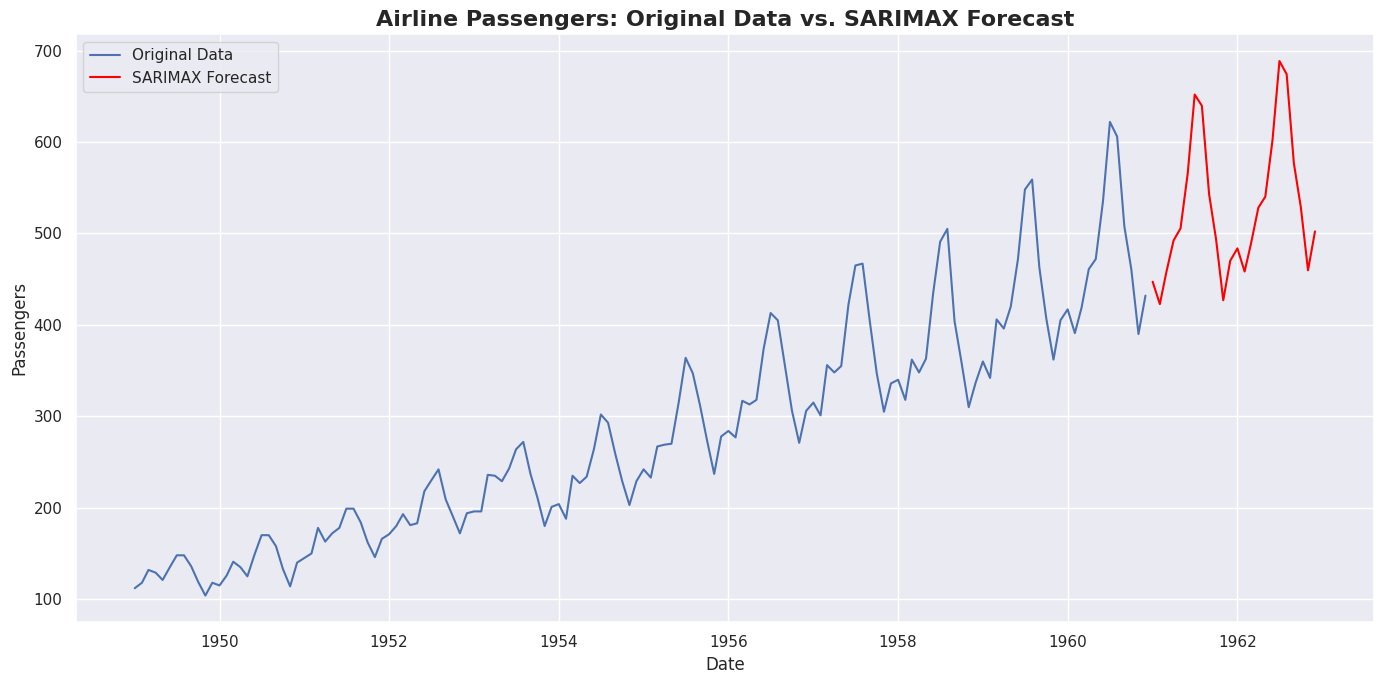

In [ ]:
# Define the number of future periods to forecast
n_forecast = 24 # e.g., 24 months into the future

# Get predictions (forecast)
# 'start' and 'end' define the range for prediction.
# To forecast into the future, we set 'start' to the end of the observed data
# and 'end' to 'n_forecast' steps beyond that.
forecast_start_index = len(df)
forecast_end_index = len(df) + n_forecast - 1

# Create a date range for the forecast
last_date = df.index[-1]
forecast_dates = pd.date_range(start=last_date, periods=n_forecast + 1, freq='MS')[1:] # Exclude the last historical date

# Make predictions
predictions = model_fit.predict(start=forecast_start_index, end=forecast_end_index, dynamic=False)
predictions.index = forecast_dates

# Plot the original data and the forecast
plt.figure(figsize=(14, 7))
plt.plot(df['Passengers'], label='Original Data')
plt.plot(predictions, label='SARIMAX Forecast', color='red')

plt.title('Airline Passengers: Original Data vs. SARIMAX Forecast', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Passengers', fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import requests

# URL of the public dataset
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'

# File name to save it as
file_name = 'airline_passengers.csv'

# Download the file
response = requests.get(url)
with open(file_name, 'wb') as f:
    f.write(response.content)

print(f"'{file_name}' downloaded successfully.")


'airline_passengers.csv' downloaded successfully.
